# 3D objektumdetekció CenterPointtal nuScenes adatokon

Ebben a gyakorlatban egy teljes, reprodukálható MMDetection3D munkafolyamatot építünk fel Google Colabban: környezettelepítés, a nuScenes mini adatok előkészítése, scene-szintű train/val/test felosztás, előre tanított CenterPoint modell inferenciája és hivatalos nuScenes-kiértékelése.

A notebook végére képes leszel:

- saját MMDetection3D forkot Colabban telepíteni;
- a nuScenes `v1.0-mini` részhalmazt letölteni és a `tools/create_data.py` segítségével feldolgozni;
- scene-szintű, módosítható arányú train/val/test splitet készíteni adatszivárgás nélkül;
- az `init_model` és `inference_detector` API-val pontfelhőn inferenciát futtatni;
- a CenterPoint modellt a nuScenes mAP, NDS és TP-hibametrikáival kiértékelni.

> **Colab:** válaszd a **Runtime / Change runtime type / T4 GPU** beállítást.

## Hogyan használd a notebookot?

A cellák elején háromféle jelölést találsz:

- **FÓKUSZ:** értsd meg a gondolatmenetet, olvasd végig a kódot, és a feladatokban módosítsd is;
- **FUTTASD – NE MÓDOSÍTSD:** szükséges infrastruktúra vagy hosszú segédkód; futtasd sorrendben, de nem kell soronként megtanulnod;
- **OPCIONÁLIS / HALADÓ:** költséges vagy továbbvezető rész.


| Cellák | Jelölés | Tartalom | Mit tegyél? |
|---:|---|---|---|
| **2–6** | **FUTTASD – NE MÓDOSÍTSD** | Python, CUDA és MMDetection3D telepítése | Állíts be T4 GPU-t, futtasd sorrendben, majd a 6. cellában ellenőrizd a verziókat. |
| **7–12** | **FUTTASD**, a 9., 10. és 12. cella **FÓKUSZ** | nuScenes mini letöltése és info-fájlok készítése | A parancsokat nem kell átírni; értsd meg a scene, sample és info-fájl fogalmát. |
| **13–16** | **FÓKUSZ** | Scene-szintű train/val/test split | Kövesd végig a scene-ek csoportosítását, módosítsd a ratio/seed értékeket, ellenőrizd a diszjunkt tokeneket. |
| **17–18** | **FUTTASD** | Config és előre tanított checkpoint letöltése | Ellenőrizd, melyik CenterPoint-változatot használjuk; a letöltőkódot ne módosítsd. |
| **19–22** | **KIEMELT FÓKUSZ** | Dataset pipeline, `init_model`, `inference_detector`, predikciók és BEV-ábra | Ez a notebook központi része: értsd meg az inputot, a modell kimenetét és a score-küszöb hatását. |
| **23–25** | **FÓKUSZ** | Hivatalos nuScenes-kiértékelés | A 24. cellát futtasd változtatás nélkül; a 25. cellában értelmezd a mAP, NDS és hibametrikákat. |
| **26–32** | **OPCIONÁLIS / HALADÓ** | Saját splithez GT-adatbázis, rövid finomhangolás és összehasonlítás | Csak tanítási kísérlethez szükséges. A 29. cella alapból nem indít tréninget. |
| **33–34** | **FÓKUSZ ROS2-integráció esetén** | Egyszerű, sorosítható detekciós kimenet | Értsd meg a koordináta-rendszer, időbélyeg és üzenetmezők kapcsolatát. |
| **35–36** | **FÓKUSZ** | Összefoglalás és önálló feladatok | Ellenőrizd a megértést, majd oldd meg a feladatokat. |

## 0. Környezet és telepítés

> **FUTTASD – NE MÓDOSÍTSD.** A 3–6. cella infrastruktúrát készít elő. Nem kell a telepítőparancsokat megtanulnod; a sorrendet, az újraindításokat és a 6. cella ellenőrző kimenetét kövesd.

Az MMDetection3D v1.4.0 nem kompatibilis a Colab új Python 3.13 környezetével, ezért a notebook Python 3.10-es környezetet hoz létre. A GPU-t azonban nem a Python vagy a PyTorch telepíti: azt a Colabnak kell a virtuális géphez rendelnie.

Még az első kódcella előtt válaszd a **Runtime / Change runtime type / T4 GPU** beállítást. A cella először az `nvidia-smi` paranccsal ellenőrzi a fizikai GPU-t, és csak ezután cseréli le a Python-környezetet.

A telepítés során két egyszeri automatikus újraindítás történik:

1. a 3. cella Python 3.10-re vált;
2. az 5. cella telepíti a rögzített NumPy/PyTorch/MMCV bináris stacket, majd tiszta folyamatot indít.

Mindkét újracsatlakozás után futtasd ismét a notebookot a **Runtime / Run all** paranccsal. A markerfájlok miatt a kész lépések nem ismétlődnek. A stack PyTorch 2.1.0 + CUDA 12.1, NumPy 1.26.4 és MMCV 2.1.0 verziókat használ.

A projekt régi `setup.py develop` alapú editable telepítése ütközhet a modern pip-pel. Ezért a notebook egy `.pth` fájllal közvetlenül a klónozott fork forráskönyvtárát köti be a Python környezetbe. A fork módosításai így új csomagtelepítés nélkül érvényesülnek. Saját fork vagy kurzus-branch használatához módosítsd a `REPO_URL` és `REPO_REF` értékét.

In [ ]:
import platform
import subprocess
import sys
from pathlib import Path

REQUIRED_PYTHON = (3, 10)
IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()

def get_nvidia_smi():
    try:
        return subprocess.run(
            ["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
            check=True,
            capture_output=True,
            text=True,
        ).stdout.strip()
    except (FileNotFoundError, subprocess.CalledProcessError):
        return ""

hardware_gpu = get_nvidia_smi()
assert hardware_gpu, (
    "A Colab nem rendelt GPU-t ehhez a runtime-hoz. Válaszd a "
    "Runtime / Change runtime type / T4 GPU beállítást, majd indítsd újra a cellát."
)
print(f"Colab GPU: {hardware_gpu}")

if sys.version_info[:2] != REQUIRED_PYTHON:
    assert IN_COLAB, "A notebook Python 3.10 környezetet igényel."
    print(
        f"A jelenlegi Python {platform.python_version()}; átváltás Python 3.10-re. "
        "A runtime egyszer automatikusan újraindul."
    )
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "setuptools>=75",
            "wheel",
            "https://github.com/conda-incubator/condacolab/archive/main.zip",
        ],
        check=True,
    )
    import condacolab

    condacolab.install(python_version="3.10")
else:
    print(f"Kompatibilis Python-környezet: {platform.python_version()}")

Colab GPU: Tesla T4, 580.82.07
Kompatibilis Python-környezet: 3.10.22


In [ ]:
import os
import subprocess
from pathlib import Path

# Cseréld le a saját forkod URL-jére. Az alapérték önmagában is futtatható.
REPO_URL = "https://github.com/open-mmlab/mmdetection3d.git"
REPO_REF = "v1.4.0"
REPO_DIR = Path("/content/mmdetection3d")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_REF, REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    print(f"Már létezik, nem klónozzuk újra: {REPO_DIR}")

# MMDetection3D v1.4.0 még a NumPy 1.24-ben eltávolított np.long aliast használja.
dbsampler_path = REPO_DIR / "mmdet3d/datasets/transforms/dbsampler.py"
dbsampler_source = dbsampler_path.read_text(encoding="utf-8")
legacy_expression = "dtype=np.long)"
fixed_expression = "dtype=np.int64)"
if legacy_expression in dbsampler_source:
    dbsampler_path.write_text(
        dbsampler_source.replace(legacy_expression, fixed_expression),
        encoding="utf-8",
    )
    print("NumPy kompatibilitási patch alkalmazva: np.long -> np.int64")
else:
    assert fixed_expression in dbsampler_source, (
        f"Nem található a várt DB sampler kódrészlet: {dbsampler_path}"
    )
    print("A NumPy kompatibilitási patch már alkalmazva van.")

os.chdir(REPO_DIR)
print(subprocess.run(["git", "rev-parse", "--short", "HEAD"], check=True, capture_output=True, text=True).stdout.strip())

Már létezik, nem klónozzuk újra: /content/mmdetection3d
A NumPy kompatibilitási patch már alkalmazva van.
fe25f7a


In [ ]:
import site
import subprocess
import sys
from pathlib import Path

from IPython import get_ipython

REPO_DIR = Path("/content/mmdetection3d")
STACK_MARKER = Path("/content/.mmdet3d_py310_torch210_cu121_data_v3_ready")
assert REPO_DIR.exists(), "Előbb futtasd a repository klónozását végző 4. cellát."

def pip_install(*packages, extra_args=(), quiet=True):
    command = [sys.executable, "-m", "pip", "install"]
    if quiet:
        command.append("-q")
    command.extend([*extra_args, *packages])
    print("Telepítés:", " ".join(packages))
    subprocess.run(command, check=True)

restart_required = not STACK_MARKER.exists()
if restart_required:
    # PyTorch 2.1 cpp_extension a pkg_resources.packaging exportot használja.
    pip_install("pip<25", "setuptools==69.5.1", "packaging==24.1", "wheel")
    pip_install(
        "torch==2.1.0+cu121",
        "torchvision==0.16.0+cu121",
        "torchaudio==2.1.0+cu121",
        extra_args=("--extra-index-url", "https://download.pytorch.org/whl/cu121"),
    )
    pip_install(
        "numpy==1.26.4",
        "mmengine==0.10.7",
        "mmdet==3.3.0",
        "nuscenes-devkit==1.2.0",
        "lyft-dataset-sdk==0.0.8",
        "scikit-image==0.24.0",
        "numba==0.60.0",
        "plyfile",
        "trimesh",
        "tensorboard",
    )
    pip_install(
        "mmcv==2.1.0",
        extra_args=("-f", "https://download.openmmlab.com/mmcv/dist/cu121/torch2.1/index.html"),
    )
else:
    print("A rögzített bináris és adatkonverter stack már telepítve van.")

source_path = str(REPO_DIR.resolve())
pth_path = Path(site.getsitepackages()[0]) / "mmdetection3d_source.pth"
pth_path.write_text(source_path + "\n", encoding="utf-8")
if source_path not in sys.path:
    sys.path.insert(0, source_path)
print(f"MMDetection3D forrás bekötve: {pth_path} -> {source_path}")

if restart_required:
    STACK_MARKER.touch()
    print("A bináris csomagok telepítve. A kernel most egyszer újraindul.")
    get_ipython().kernel.do_shutdown(restart=True)

A rögzített bináris és adatkonverter stack már telepítve van.
MMDetection3D forrás bekötve: /content/.pixi/envs/default/lib/python3.10/site-packages/mmdetection3d_source.pth -> /content/mmdetection3d


In [ ]:
import platform
import subprocess
import sys
from importlib.metadata import version
from pathlib import Path

REQUIRED_PYTHON = (3, 10)
REPO_DIR = Path("/content/mmdetection3d")
source_path = str(REPO_DIR.resolve())
if source_path not in sys.path:
    sys.path.insert(0, source_path)

hardware_gpu = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
    check=True,
    capture_output=True,
    text=True,
).stdout.strip()

import torch
import mmcv
import mmdet
import mmdet3d
import mmengine
from mmcv import ops
from pkg_resources import packaging as pkg_resources_packaging
from torch.utils.cpp_extension import CUDA_HOME

print(f"Python {platform.python_version()}")
print(f"PyTorch {torch.__version__}, CUDA runtime {torch.version.cuda}")
print(f"GPU hardver: {hardware_gpu}")
print(f"PyTorch GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nem elérhető'}")
print(f"MMEngine {mmengine.__version__}")
print(f"MMCV {mmcv.__version__}")
print(f"MMDetection {mmdet.__version__}")
print(f"MMDetection3D {mmdet3d.__version__}")
print(f"setuptools {version('setuptools')}, packaging {pkg_resources_packaging.__version__}")
print(f"CUDA_HOME: {CUDA_HOME}")

assert sys.version_info[:2] == REQUIRED_PYTHON
assert hardware_gpu, "A Colab runtime-hoz nincs GPU rendelve."
assert torch.version.cuda == "12.1"
assert torch.cuda.is_available(), (
    "Az nvidia-smi látja a GPU-t, de a PyTorch nem tudta inicializálni. "
    "Válaszd a Runtime / Disconnect and delete runtime parancsot, majd indíts "
    "új T4 GPU runtime-ot és futtasd újra a notebookot az elejétől."
)
assert callable(ops.nms)
print("A GPU, az MMCV CUDA-operátorok és a PyTorch build-eszközök elérhetők.")

Python 3.10.22
PyTorch 2.1.0+cu121, CUDA runtime 12.1
GPU hardver: Tesla T4, 580.82.07
PyTorch GPU: Tesla T4
MMEngine 0.10.7
MMCV 2.1.0
MMDetection 3.3.0
MMDetection3D 1.4.0
setuptools 69.5.1, packaging 24.0
CUDA_HOME: /usr/local/cuda
A GPU, az MMCV CUDA-operátorok és a PyTorch build-eszközök elérhetők.


## 1. A nuScenes mini letöltése

> **FUTTASD – NE MÓDOSÍTSD.** A 8. cella csak letölti és kicsomagolja az adatot. A 9. cellában viszont figyeld meg a scene és sample fogalmát, mert erre épül a későbbi split.

A nuScenes teljes trainval készlete több száz GB, ezért a gyakorlatban a 10 scene-ből és 404 annotált kulcsképkockából álló `v1.0-mini` változatot használjuk. Az archívum mérete megközelítőleg 4 GB.

A nuScenes egy **scene** alatt időben összefüggő vezetési szekvenciát ért. A későbbi felosztást scene-szinten kell elvégezni: ha ugyanazon útvonal szomszédos képkockái külön splitekbe kerülnének, az adatszivárgást okozna.

In [ ]:
import subprocess
from pathlib import Path

REPO_DIR = Path("/content/mmdetection3d")
DATA_ROOT = REPO_DIR / "data" / "nuscenes"
ARCHIVE = Path("/content/v1.0-mini.tgz")
NUSCENES_URL = "https://www.nuscenes.org/data/v1.0-mini.tgz"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

if not ARCHIVE.exists():
    subprocess.run(["wget", "-c", NUSCENES_URL, "-O", str(ARCHIVE)], check=True)
else:
    print(f"Az archívum már létezik: {ARCHIVE}")

if not (DATA_ROOT / "v1.0-mini").exists():
    subprocess.run(["tar", "-xzf", str(ARCHIVE), "-C", str(DATA_ROOT)], check=True)
else:
    print("A v1.0-mini már ki van csomagolva.")

Az archívum már létezik: /content/v1.0-mini.tgz
A v1.0-mini már ki van csomagolva.


In [ ]:
from nuscenes.nuscenes import NuScenes

nusc = NuScenes(version="v1.0-mini", dataroot=str(DATA_ROOT), verbose=False)
print(f"Scene-ek száma: {len(nusc.scene)}")
print(f"Annotált minták száma: {len(nusc.sample)}")
print(f"Első scene: {nusc.scene[0]['name']} ({nusc.scene[0]['description'][:80]}...)")

Scene-ek száma: 10
Annotált minták száma: 404
Első scene: scene-0061 (Parked truck, construction, intersection, turn left, following a van...)


## 2. Info-fájlok készítése a `create_data.py` segítségével

> **FÓKUSZ.** A 11. cella hosszú adatkonverziós segédkódját nem kell átírnod. Értsd meg, miért kell a nyers nuScenes adatokból MMDetection3D info-fájl és ground-truth adatbázis; a 12. cellában vizsgáld meg az eredményt.

A nyers nuScenes JSON táblák és szenzorfájlok helyett az MMDetection3D előre feldolgozott `.pkl` info-fájlokat használ. Ezek többek között a LiDAR-fájlok relatív útvonalát, a koordináta-transzformációkat és a 3D annotációkat tartalmazzák.

- `--version v1.0-mini`: a devkit rögzített `mini_train` és `mini_val` scene-listáit használja;
- `--max-sweeps 5`: egy kulcsképkockához legfeljebb öt korábbi LiDAR sweep metaadata kerül be;
- `--extra-tag nuscenes`: a kimeneti fájlnevek előtagja.

A parancs ground-truth adatbázist is készít az objektummintavételezéses augmentációhoz. Ez néhány percig tarthat.

In [ ]:
import os
import subprocess
import sys
from pathlib import Path

REPO_DIR = Path("/content/mmdetection3d")
DATA_ROOT = REPO_DIR / "data" / "nuscenes"
official_train_path = DATA_ROOT / "nuscenes_infos_train.pkl"
official_val_path = DATA_ROOT / "nuscenes_infos_val.pkl"
conversion_log = Path("/content/create_nuscenes_data.log")

if not (official_train_path.exists() and official_val_path.exists()):
    command = [
        sys.executable,
        "-m", "tools.create_data",
        "nuscenes",
        "--root-path", str(DATA_ROOT),
        "--out-dir", str(DATA_ROOT),
        "--extra-tag", "nuscenes",
        "--version", "v1.0-mini",
        "--max-sweeps", "5",
    ]
    process_env = os.environ.copy()
    process_env["PYTHONPATH"] = os.pathsep.join(
        [str(REPO_DIR), process_env.get("PYTHONPATH", "")]
    ).rstrip(os.pathsep)

    with conversion_log.open("w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            command,
            cwd=REPO_DIR,
            env=process_env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )
        for line in process.stdout:
            print(line, end="")
            log_file.write(line)
        return_code = process.wait()
    if return_code != 0:
        raise RuntimeError(
            f"A create_data.py hibával leállt (exit code: {return_code}). "
            f"A teljes napló itt található: {conversion_log}"
        )
else:
    print("Az info-fájlok már léteznek, az előkészítést kihagyjuk.")

Az info-fájlok már léteznek, az előkészítést kihagyjuk.


In [ ]:
official_train = mmengine.load(official_train_path)
official_val = mmengine.load(official_val_path)

print(f"Hivatalos mini_train minták: {len(official_train['data_list'])}")
print(f"Hivatalos mini_val minták:   {len(official_val['data_list'])}")
print("Első rekord mezői:", sorted(official_train["data_list"][0].keys()))

assert len(official_train["data_list"]) + len(official_val["data_list"]) == len(nusc.sample)

Hivatalos mini_train minták: 323
Hivatalos mini_val minták:   81
Első rekord mezői: ['cam_instances', 'ego2global', 'images', 'instances', 'lidar_points', 'sample_idx', 'timestamp', 'token']


## 3. Saját train/val/test split

> **FÓKUSZ.** A 14–16. cella az első olyan kódblokk, amelyet érdemes soronként megérteni és módosítani. Keresd a scene-szintű csoportosítást, a reprodukálható keverést, az arányokból számított darabszámokat és a diszjunkt tokenek ellenőrzését.

A `create_data.py` a nuScenes devkit beépített mini felosztását követi, amely csak train és val részt definiál. Oktatási vagy fejlesztési célra az összes mini scene-t újraoszthatjuk három részre.

Az alábbi cellában a `SPLIT_RATIOS` értékei módosítják az arányokat; összegüknek 1-nek kell lennie. A `SEED` biztosítja a reprodukálhatóságot. Tíz scene mellett egy scene 10 százalékpontnak felel meg, ezért ennél finomabb arány itt nem értelmezhető.

> **Fontos:** saját splitnél a validációs metrikák összehasonlíthatósága megszűnik a hivatalos nuScenes benchmarkkal. A későbbi hivatalos NDS/mAP mérés ezért az érintetlen `nuscenes_infos_val.pkl` fájlt használja.

In [ ]:
import math
import random
from collections import defaultdict
from copy import deepcopy

SPLIT_RATIOS = {"train": 0.6, "val": 0.2, "test": 0.2}
SEED = 42

assert set(SPLIT_RATIOS) == {"train", "val", "test"}
assert math.isclose(sum(SPLIT_RATIOS.values()), 1.0)
assert all(ratio > 0 for ratio in SPLIT_RATIOS.values())

all_records = official_train["data_list"] + official_val["data_list"]
sample_to_scene = {sample["token"]: sample["scene_token"] for sample in nusc.sample}
scene_to_records = defaultdict(list)

for record in all_records:
    sample_token = record["token"]
    assert sample_token in sample_to_scene, f"Ismeretlen nuScenes sample token: {sample_token}"
    scene_to_records[sample_to_scene[sample_token]].append(record)

assert sum(map(len, scene_to_records.values())) == len(all_records)
scene_tokens = sorted(scene_to_records)
random.Random(SEED).shuffle(scene_tokens)
print(f"Felosztható scene-ek: {len(scene_tokens)}")

Felosztható scene-ek: 10


In [ ]:
def allocate_scene_counts(total, ratios):
    """Egész scene-darabszámok a legnagyobb maradék módszerével."""
    exact = {name: total * ratio for name, ratio in ratios.items()}
    counts = {name: int(value) for name, value in exact.items()}
    remainder = total - sum(counts.values())
    order = sorted(ratios, key=lambda name: exact[name] - counts[name], reverse=True)
    for name in order[:remainder]:
        counts[name] += 1
    return counts

scene_counts = allocate_scene_counts(len(scene_tokens), SPLIT_RATIOS)
assert all(count > 0 for count in scene_counts.values()), "Minden splithez legalább egy scene szükséges."

split_scenes = {}
start = 0
for split_name in ("train", "val", "test"):
    stop = start + scene_counts[split_name]
    split_scenes[split_name] = set(scene_tokens[start:stop])
    start = stop

assert set.union(*split_scenes.values()) == set(scene_tokens)
assert not (split_scenes["train"] & split_scenes["val"])
assert not (split_scenes["train"] & split_scenes["test"])
assert not (split_scenes["val"] & split_scenes["test"])

scene_name = {scene["token"]: scene["name"] for scene in nusc.scene}
for split_name, tokens in split_scenes.items():
    print(f"{split_name:>5}: {len(tokens)} scene - {sorted(scene_name[token] for token in tokens)}")

train: 6 scene - ['scene-0061', 'scene-0553', 'scene-0655', 'scene-1077', 'scene-1094', 'scene-1100']
  val: 2 scene - ['scene-0103', 'scene-0796']
 test: 2 scene - ['scene-0757', 'scene-0916']


In [ ]:
SPLIT_WRITER_VERSION = "token-v2"
print(f"Custom split writer: {SPLIT_WRITER_VERSION}")

custom_paths = {}
custom_records = {}

for split_name, selected_scenes in split_scenes.items():
    records = [
        deepcopy(record)
        for scene_token in selected_scenes
        for record in scene_to_records[scene_token]
    ]
    for sample_idx, record in enumerate(records):
        record["sample_idx"] = sample_idx

    payload = {
        "metainfo": deepcopy(official_train["metainfo"]),
        "data_list": records,
    }
    output_path = DATA_ROOT / f"nuscenes_custom_infos_{split_name}.pkl"
    mmengine.dump(payload, output_path)
    custom_paths[split_name] = output_path
    custom_records[split_name] = records
    print(f"{split_name:>5}: {len(records):>3} minta -> {output_path.name}")

all_custom_tokens = [
    record["token"]
    for records in custom_records.values()
    for record in records
]
record_count = sum(map(len, custom_records.values()))
unique_token_count = len(set(all_custom_tokens))
assert record_count == len(all_records), (
    f"Mintavesztés történt: {record_count} / {len(all_records)} rekord maradt meg."
)
assert unique_token_count == len(all_records), (
    f"A tokenek nem egyediek: {unique_token_count} / {len(all_records)} egyedi token."
)
for split_name, records in custom_records.items():
    sample_indices = [record["sample_idx"] for record in records]
    assert sample_indices == list(range(len(records))), (
        f"A {split_name} split sample_idx mezői nem folytonosak."
    )
print("A splitek diszjunktak, minden token egyedi, a sample_idx mezők folytonosak.")

Custom split writer: token-v2
train: 242 minta -> nuscenes_custom_infos_train.pkl
  val:  80 minta -> nuscenes_custom_infos_val.pkl
 test:  82 minta -> nuscenes_custom_infos_test.pkl
A splitek diszjunktak, minden token egyedi, a sample_idx mezők folytonosak.


## 4. Előre tanított CenterPoint modell

> **FUTTASD.** A 18. cella config- és checkpoint-útvonalakat állít be, majd letölti a súlyokat. Jegyezd meg, melyik modellváltozatot használjuk, de a letöltési URL-t és a segédkódot nem kell módosítanod.

A választott modell a 0,2 m-es pillar reprezentációt, SECOND backbone-t, SECFPN neck-et és circle NMS-t használó CenterPoint. A modellzoo adatai szerint körülbelül 4,6 GB GPU-memóriát igényel, ezért a nuScenes CenterPoint variánsok közül ez alkalmas leginkább ingyenes Colab GPU-ra.

A checkpointot a teljes nuScenes train spliten tanították. Az itt használt mini adatok célja az API és a kiértékelési folyamat gyakorlása, nem a közölt modellezoo-eredmény reprodukálása.

In [ ]:
MODEL_CONFIG = REPO_DIR / "configs/centerpoint/centerpoint_pillar02_second_secfpn_head-circlenms_8xb4-cyclic-20e_nus-3d.py"
CHECKPOINT = REPO_DIR / "checkpoints/centerpoint_pillar02_nuscenes.pth"
CHECKPOINT_URL = (
    "https://download.openmmlab.com/mmdetection3d/v1.0.0_models/centerpoint/"
    "centerpoint_02pillar_second_secfpn_circlenms_4x8_cyclic_20e_nus/"
    "centerpoint_02pillar_second_secfpn_circlenms_4x8_cyclic_20e_nus_20220811_031844-191a3822.pth"
)
CHECKPOINT.parent.mkdir(exist_ok=True)

if not CHECKPOINT.exists():
    subprocess.run(["wget", "-c", CHECKPOINT_URL, "-O", str(CHECKPOINT)], check=True)
else:
    print(f"A checkpoint már létezik: {CHECKPOINT}")

A checkpoint már létezik: /content/mmdetection3d/checkpoints/centerpoint_pillar02_nuscenes.pth


### Inference az MMDetection3D Python API-val

> **KIEMELT FÓKUSZ.** A 20–22. cella a gyakorlat központi része. Kövesd végig, hogyan készül a datasetből több sweepet tartalmazó input, hogyan épül fel a modell, milyen objektum a predikció, és hogyan lesz belőle táblázat és BEV-ábra.

Az `init_model` a konfigurációból felépíti a hálózatot, betölti a checkpointot, GPU-ra mozgatja és evaluation módba állítja. Az `inference_detector` fájlútvonalat, NumPy-tömböt vagy ezek listáját fogadja.

A CenterPoint checkpoint 10 sweepből álló bemenetre készült. Egyetlen `.bin` fájl nem tartalmazza a korábbi sweep-ek útvonalát és transzformációját, ezért először a hivatalos `NuScenesDataset` tesztpipeline-jával állítjuk elő az időben és térben összeillesztett 5D ponttömböt. Ezt a tömböt adjuk át az `inference_detector` API-nak. Így az API-példa ugyanazt az inputreprezentációt használja, mint a teljes kiértékelés.

Az MMDetection3D egyes verziói közvetlenül egy `Det3DDataSample` objektumot adnak vissza, a kurzushoz használt fork viszont `(result, preprocessed_data)` tuple-t. A következő cella mindkét szerződést kezeli.

A predikált és ground-truth dobozok ugyanabban a **LiDAR-koordinátarendszerben** vannak: pozitív $x$ előre, pozitív $y$ balra, pozitív $z$ felfelé; a yaw a $z$ tengely körül értendő. A BEV-ábra közvetlenül az MMDetection3D által számított dobozsarkokat használja. A ground truth szaggatott, a predikció folytonos kontúrral jelenik meg; a szín mindkettőnél az objektumosztályt jelöli.

In [ ]:
from copy import deepcopy
from pathlib import Path

from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmdet3d.apis import inference_detector, init_model
from mmdet3d.registry import DATASETS

REPO_DIR = Path("/content/mmdetection3d")
DATA_ROOT = REPO_DIR / "data" / "nuscenes"
official_val_path = DATA_ROOT / "nuscenes_infos_val.pkl"
assert official_val_path.exists(), f"Hiányzó annotációs fájl: {official_val_path}"

full_cfg = Config.fromfile(MODEL_CONFIG)
init_default_scope(full_cfg.get("default_scope", "mmdet3d"))

# Ugyanaz a 10-sweepes előfeldolgozás, amelyet a hivatalos tesztpipeline használ.
dataset_cfg = deepcopy(full_cfg.test_dataloader.dataset)
dataset_cfg["data_root"] = str(DATA_ROOT)
dataset_cfg["ann_file"] = official_val_path.name
dataset_cfg["lazy_init"] = False
test_dataset = DATASETS.build(dataset_cfg)
sample_index = 0
data_info = test_dataset.get_data_info(sample_index)
prepared_sample = test_dataset[sample_index]
multi_sweep_points = prepared_sample["inputs"]["points"].cpu().numpy()

# A ground truth ugyanabban a LiDAR-frame-ben van, mint a modell predikciói.
eval_ann_info = data_info["eval_ann_info"]
gt_labels = eval_ann_info["gt_labels_3d"]
gt_valid = gt_labels >= 0
gt_labels = gt_labels[gt_valid].astype(int)
gt_boxes_3d = eval_ann_info["gt_bboxes_3d"][gt_valid]
gt_box_corners = gt_boxes_3d.corners.detach().cpu().numpy()

# Az API már előfeldolgozott ponttömböt kap, ezért itt nem töltjük be újra a sweep-eket.
inference_cfg = Config.fromfile(MODEL_CONFIG)
inference_cfg.test_dataloader.dataset.pipeline = [
    dict(
        type="LoadPointsFromFile",
        coord_type="LIDAR",
        load_dim=5,
        use_dim=5,
    ),
    dict(type="Pack3DDetInputs", keys=["points"]),
]

model = init_model(inference_cfg, str(CHECKPOINT), device="cuda:0")
sample_token = data_info["token"]
sample = nusc.get("sample", sample_token)
lidar_record = nusc.get("sample_data", sample["data"]["LIDAR_TOP"])
lidar_path = DATA_ROOT / lidar_record["filename"]

inference_output = inference_detector(model, multi_sweep_points)
if isinstance(inference_output, tuple):
    result, inference_data = inference_output
else:
    result, inference_data = inference_output, None

assert hasattr(result, "pred_instances_3d"), type(result)
print(type(result).__name__, lidar_path)
print(f"API-bemenet: {len(multi_sweep_points):,} pont, {multi_sweep_points.shape[1]} jellemző")
print(f"Ground-truth objektumok: {len(gt_labels)}")
print("Időtartomány [s]:", multi_sweep_points[:, 4].min(), multi_sweep_points[:, 4].max())

10/30 19:44:06 - mmengine - INFO - ------------------------------
10/30 19:44:06 - mmengine - INFO - The length of test dataset: 81
10/30 19:44:06 - mmengine - INFO - The number of instances per category in the dataset:
+----------------------+--------+
| category             | number |
+----------------------+--------+
| car                  | 2568   |
| truck                | 124    |
| construction_vehicle | 0      |
| bus                  | 41     |
| trailer              | 0      |
| barrier              | 0      |
| motorcycle           | 259    |
| bicycle              | 52     |
| pedestrian           | 1358   |
| traffic_cone         | 39     |
+----------------------+--------+
Loads checkpoint by local backend from path: /content/mmdetection3d/checkpoints/centerpoint_pillar02_nuscenes.pth
Det3DDataSample /content/mmdetection3d/data/nuscenes/samples/LIDAR_TOP/n008-2018-08-01-15-16-36-0400__LIDAR_TOP__1533151603547590.pcd.bin
API-bemenet: 219,288 pont, 5 jellemző
Ground-truth o

/content/mmdetection3d/mmdet3d/models/task_modules/coders/centerpoint_bbox_coders.py:207: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.post_center_range = torch.tensor(


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

predictions = result.pred_instances_3d
score_threshold = 0.30
keep = predictions.scores_3d >= score_threshold
boxes = predictions.bboxes_3d.tensor[keep].detach().cpu().numpy()
box_corners = predictions.bboxes_3d[keep].corners.detach().cpu().numpy()
scores = predictions.scores_3d[keep].detach().cpu().numpy()
labels = predictions.labels_3d[keep].detach().cpu().numpy().astype(int)
classes = model.dataset_meta["classes"]
class_colors = {
    class_name: plt.get_cmap("tab10")(index % 10)
    for index, class_name in enumerate(classes)
}
columns = ["class", "score", "x", "y", "z", "length", "width", "height", "yaw"]

prediction_table = pd.DataFrame(
    [
        {
            "class": classes[label],
            "score": score,
            "x": box[0],
            "y": box[1],
            "z": box[2],
            "length": box[3],
            "width": box[4],
            "height": box[5],
            "yaw": box[6],
        }
        for box, score, label in zip(boxes, scores, labels)
    ],
    columns=columns,
)
print(f"{len(prediction_table)} detekció a {score_threshold:.2f} küszöb felett")
prediction_table.sort_values("score", ascending=False).head(20).style.format(
    {"score": "{:.3f}", "x": "{:.1f}", "y": "{:.1f}", "z": "{:.1f}", "yaw": "{:.2f}"}
)

36 detekció a 0.30 küszöb felett


,class,score,x,y,z,length,width,height,yaw
5,pedestrian,0.864,5.8,-0.2,-1.5,0.713333,0.613779,1.716953,-1.05
0,car,0.802,-3.3,-23.0,-2.9,4.654168,1.972785,1.738808,-1.51
6,pedestrian,0.767,7.5,17.4,-1.0,0.676059,0.653149,1.758217,-1.12
1,car,0.743,0.1,-19.9,-2.8,4.595983,1.933983,1.640524,1.57
7,pedestrian,0.721,-6.1,32.1,-0.8,0.674376,0.673103,1.783754,0.58
8,pedestrian,0.703,-8.5,37.2,-0.6,0.710419,0.667583,1.807489,-0.17
9,pedestrian,0.687,6.7,-0.2,-1.6,0.654700,0.602930,1.735825,-1.32
10,pedestrian,0.639,-11.4,33.4,-1.0,0.629625,0.644021,1.735775,2.73
2,car,0.574,-5.9,42.7,-0.5,4.596364,1.946501,1.701035,-1.57
11,pedestrian,0.559,-9.4,19.1,-1.2,0.696118,0.676135,1.805186,1.29


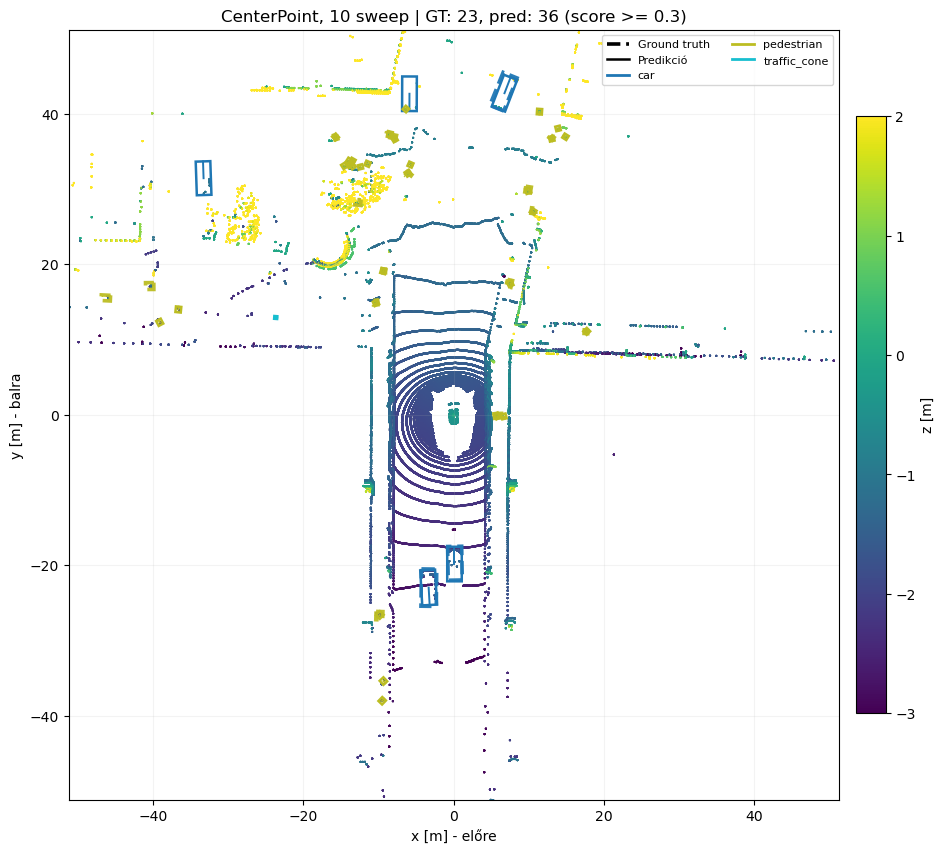

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon

points = multi_sweep_points
keyframe_mask = np.isclose(points[:, 4], 0.0)
history_mask = ~keyframe_mask
fig, ax = plt.subplots(figsize=(11, 10))

ax.scatter(
    points[history_mask, 0],
    points[history_mask, 1],
    s=0.08,
    c="#c7ccd1",
    alpha=0.18,
    rasterized=True,
)
keyframe_scatter = ax.scatter(
    points[keyframe_mask, 0],
    points[keyframe_mask, 1],
    s=0.25,
    c=points[keyframe_mask, 2],
    cmap="viridis",
    vmin=-3,
    vmax=2,
    rasterized=True,
)

present_classes = set()

# Ground truth: osztályszín, vastag szaggatott kontúr.
for corners, label in zip(gt_box_corners, gt_labels):
    class_name = classes[label]
    color = class_colors[class_name]
    present_classes.add(class_name)
    footprint = corners[[0, 3, 7, 4], :2]
    ax.add_patch(
        Polygon(
            footprint,
            closed=True,
            fill=False,
            edgecolor=color,
            linewidth=2.6,
            linestyle="--",
            alpha=0.95,
            zorder=3,
        )
    )

# Predikció: osztályszín, folytonos kontúr és irányjelölő.
for corners, label, score in zip(box_corners, labels, scores):
    class_name = classes[label]
    color = class_colors[class_name]
    present_classes.add(class_name)
    footprint = corners[[0, 3, 7, 4], :2]
    ax.add_patch(
        Polygon(
            footprint,
            closed=True,
            fill=False,
            edgecolor=color,
            linewidth=1.8,
            linestyle="-",
            zorder=4,
        )
    )
    center = footprint.mean(axis=0)
    front_center = footprint[[2, 3]].mean(axis=0)
    ax.plot(
        [center[0], front_center[0]],
        [center[1], front_center[1]],
        color=color,
        linewidth=1.4,
        zorder=4,
    )

point_cloud_range = full_cfg.get("point_cloud_range", [-51.2, -51.2, -5, 51.2, 51.2, 3])
ax.set(
    xlim=(point_cloud_range[0], point_cloud_range[3]),
    ylim=(point_cloud_range[1], point_cloud_range[4]),
    aspect="equal",
    xlabel="x [m] - előre",
    ylabel="y [m] - balra",
    title=(
        f"CenterPoint, 10 sweep | GT: {len(gt_labels)}, "
        f"pred: {len(labels)} (score >= {score_threshold})"
    ),
)
ax.grid(alpha=0.15)
fig.colorbar(keyframe_scatter, ax=ax, fraction=0.035, pad=0.02, label="z [m]")

style_handles = [
    Line2D([0], [0], color="black", lw=2.6, linestyle="--", label="Ground truth"),
    Line2D([0], [0], color="black", lw=1.8, linestyle="-", label="Predikció"),
]
class_handles = [
    Line2D([0], [0], color=class_colors[name], lw=2, label=name)
    for name in classes
    if name in present_classes
]
ax.legend(
    handles=style_handles + class_handles,
    loc="upper right",
    fontsize=8,
    ncol=2,
)
plt.show()

# **Preprocessing és dataloader teszt**

In [ ]:
from copy import deepcopy
from typing import Optional, Sequence
import numpy as np
from mmengine.config import Config


class PointCloudPreprocessor:
    """
    Univerzális pontfelhő előfeldolgozó (Preprocessor) MMDetection3D modellekhez.
    Feladata a bemeneti pontfelhő (nuScenes, saját mérés vagy ROS 2 PointCloud2)
    méreteinek (oszlopszám, térbeli tartomány, pontszám) a kiválasztott modellhez
    igazítása tisztán memóriában (RAM), fájlműveletek nélkül.
    """

    def __init__(
        self,
        target_dim: int = 5,
        point_cloud_range: Optional[Sequence[float]] = None,
        forward_fov_only: bool = False,
        keyframe_only: bool = False,
        reset_timestamp_col: bool = False,
        max_points: Optional[int] = None,
        min_points: int = 1,
        seed: Optional[int] = 42,
    ) -> None:
        """
        :param target_dim: A modell által várt oszlopszám (nuScenes: 5, KITTI: 4).
        :param point_cloud_range: Térbeli határok [x_min, y_min, z_min, x_max, y_max, z_max].
        :param forward_fov_only: Ha True, csak az autó előtti (x > 0) pontokat tartja meg (pl. KITTI).
        :param keyframe_only: Ha True, a többszörös (10-sweep) nuScenes adatból csak az aktuális (dt == 0)
                              kulcskockát tartja meg.
        :param reset_timestamp_col: Ha True és van 5. oszlop, lenullázza azt (nyers .bin fájloknál hasznos,
                                    ahol az 5. oszlop a ring_index, nem pedig a dt időbélyeg).
        :param max_points: Felső korlát a pontok számára (N). Ha több pont van, ritkítja (downsampling).
        :param min_points: Alsó korlát a pontok számára (N). Ha kevesebb pont van, nullákkal párnázza a sorokat.
        :param seed: Random seed a reprodukálható pontritkításhoz.
        """
        if target_dim < 3:
            raise ValueError(f"A target_dim legalább 3 kell legyen (x, y, z), kapott érték: {target_dim}")

        self.target_dim = target_dim
        self.point_cloud_range = (
            np.array(point_cloud_range, dtype=np.float32)
            if point_cloud_range is not None
            else None
        )
        self.forward_fov_only = forward_fov_only
        self.keyframe_only = keyframe_only
        self.reset_timestamp_col = reset_timestamp_col
        self.max_points = max_points
        self.min_points = max(1, min_points)
        self.rng = np.random.default_rng(seed)

    @classmethod
    def from_mmdet3d_config(
        cls,
        cfg: Config,
        keyframe_only: bool = False,
        reset_timestamp_col: bool = False,
        max_points: Optional[int] = None,
        min_points: int = 1,
    ) -> "PointCloudPreprocessor":
        """
        Automatikusan felépíti a Preprocesszort a kiválasztott MMDetection3D modell
        konfigurációs fájljából (pl. CenterPoint, PointPillars, VoxelNeXt).
        """
        # 1. Térbeli határok (point_cloud_range) kiolvasása a konfigból (mint a notebook 22. cellájában)
        pc_range = cfg.get("point_cloud_range", None)

        # 2. Elvárt oszlopszám (use_dim / load_dim) megkeresése a teszt pipeline-ban
        target_dim = 5  # alapértelmezett nuScenes érték
        pipeline = cfg.test_dataloader.dataset.pipeline
        for transform in pipeline:
            if transform.get("type") == "LoadPointsFromFile":
                use_dim = transform.get("use_dim", transform.get("load_dim", 5))
                if isinstance(use_dim, (list, tuple)):
                    target_dim = len(use_dim)
                else:
                    target_dim = int(use_dim)
                break

        # 3. Ellenőrizzük, hogy csak előre néző (x >= 0) látóteret vár-e a modell (pl. KITTI)
        forward_only = bool(pc_range is not None and pc_range[0] >= 0.0)

        return cls(
            target_dim=target_dim,
            point_cloud_range=pc_range,
            forward_fov_only=forward_only,
            keyframe_only=keyframe_only,
            reset_timestamp_col=reset_timestamp_col,
            max_points=max_points,
            min_points=min_points,
        )

    def build_inference_config(self, base_cfg: Config) -> Config:
        """
        A notebook 20. cellájának mintájára felkészíti a modell konfigurációját arra,
        hogy közvetlenül a Preprocesszor által előállított memóriabeli NumPy tömböt fogadja.
        """
        inference_cfg = deepcopy(base_cfg)
        inference_cfg.test_dataloader.dataset.pipeline = [
            dict(
                type="LoadPointsFromFile",
                coord_type="LIDAR",
                load_dim=self.target_dim,
                use_dim=self.target_dim,
            ),
            dict(type="Pack3DDetInputs", keys=["points"]),
        ]
        return inference_cfg

    def _filter_keyframe(self, points: np.ndarray) -> np.ndarray:
        """Időbeli kicsinyítés: 10 sweepből csak az aktuális (dt == 0.0) kulcskocka megtartása."""
        if self.keyframe_only and points.shape[1] >= 5:
            # A notebook 22. cellájában használt maszkolás
            keyframe_mask = np.isclose(points[:, 4], 0.0)
            points = points[keyframe_mask]
        return points

    def _filter_spatial_range(self, points: np.ndarray) -> np.ndarray:
        """Térbeli kicsinyítés: a modell látómezején (FOV / Point Cloud Range) kívüli pontok eldobása."""
        if len(points) == 0:
            return points

        mask = np.ones(len(points), dtype=bool)

        # Előre néző FOV szűrés (pl. KITTI modelleknél x > 0)
        if self.forward_fov_only:
            mask &= points[:, 0] > 0.0

        # Téglatest (Point Cloud Range) szűrés: [x_min, y_min, z_min, x_max, y_max, z_max]
        if self.point_cloud_range is not None:
            x_min, y_min, z_min, x_max, y_max, z_max = self.point_cloud_range
            mask &= (
                (points[:, 0] >= x_min) & (points[:, 0] <= x_max) &
                (points[:, 1] >= y_min) & (points[:, 1] <= y_max) &
                (points[:, 2] >= z_min) & (points[:, 2] <= z_max)
            )

        return points[mask]

    def _align_feature_dimensions(self, points: np.ndarray) -> np.ndarray:
        """
        Oszlopszám (C) igazítása:
        - Padding nullákkal (0.0), ha a bemenetnek kevesebb oszlopa van, mint amit a modell vár.
        - Kicsinyítés (levágás), ha a bemenetnek több oszlopa van, mint amit a modell vár.
        """
        num_points, current_dim = points.shape

        if current_dim < self.target_dim:
            # PADDING: hiányzó oszlopok (pl. intensity vagy dt) feltöltése 0.0-val
            padded_points = np.zeros((num_points, self.target_dim), dtype=np.float32)
            padded_points[:, :current_dim] = points
            points = padded_points
        elif current_dim > self.target_dim:
            # KICSINYÍTÉS (Csonkolás): felesleges oszlopok levágása (pl. 5-ről 4-re KITTI-hez)
            points = points[:, :self.target_dim]

        # Ha nyers 1-sweepes nuScenes .bin fájlt olvastunk be, az 5. oszlopban ring_index van,
        # amit 0.0 időbélyeg-különbségre (dt=0.0) kell állítani.
        if self.reset_timestamp_col and self.target_dim >= 5:
            points[:, 4] = 0.0

        return points

    def _align_point_count(self, points: np.ndarray) -> np.ndarray:
        """
        Pontszám (N - sorok száma) igazítása:
        - Kicsinyítés (Downsampling), ha túl sok pont van (pl. 250 000 pont helyett max 60 000).
        - Padding (sorok pótlása 0.0-val), ha túl kevés pont maradt a szűrés után.
        """
        num_points = len(points)

        # 1. KICSINYÍTÉS: véletlenszerű mintavételezés, ha a pontszám meghaladja a max_points-ot
        if self.max_points is not None and num_points > self.max_points:
            selected_indices = self.rng.choice(num_points, size=self.max_points, replace=False)
            points = points[selected_indices]

        # 2. PADDING: ha a szűrés után kevesebb pont maradt, mint a min_points (vagy 0 pont maradt)
        elif num_points < self.min_points:
            pad_rows = self.min_points - num_points
            row_padding = np.zeros((pad_rows, self.target_dim), dtype=np.float32)
            points = np.vstack((points, row_padding)) if num_points > 0 else row_padding

        return points

    def __call__(self, points: np.ndarray) -> np.ndarray:
        """
        A teljes előfeldolgozó csővezeték lefuttatása egyetlen memóriabeli pontfelhőn.
        """
        if not isinstance(points, np.ndarray):
            points = np.asarray(points)

        if points.ndim != 2 or points.shape[1] < 3:
            raise ValueError(
                f"A bemeneti pontfelhőnek (N, C>=3) alakúnak kell lennie, kapott alak: {points.shape}"
            )

        # Garantáljuk a float32 típust és a memóriabeli folytonosságot
        points = np.ascontiguousarray(points, dtype=np.float32)

        # 1. Időbeli kicsinyítés (opcionális: 10 sweep -> 1 keyframe)
        points = self._filter_keyframe(points)

        # 2. Térbeli kicsinyítés (FOV és Point Cloud Range szűrés)
        points = self._filter_spatial_range(points)

        # 3. Oszlopszám (C) padding vagy kicsinyítés
        points = self._align_feature_dimensions(points)

        # 4. Pontszám (N) kicsinyítés (downsampling) vagy padding
        points = self._align_point_count(points)

        return np.ascontiguousarray(points, dtype=np.float32)

In [ ]:
# 1. ESET: CenterPoint konfiguráció automatikus betöltése (5 oszlop, [-51.2, -51.2, -5, 51.2, 51.2, 3])
centerpoint_prep = PointCloudPreprocessor.from_mmdet3d_config(
    full_cfg,
    max_points=100_000,  # Kicsinyítés: legfeljebb 100 000 pontot engedünk át
)

# Teszt 1/A: 3 oszlopos (x, y, z) nyers mérés PADDING-elése 5 oszloposra
raw_3col = multi_sweep_points[:5000, :3]  # Levágjuk 3 oszloposra szimulációként
out_padded = centerpoint_prep(raw_3col)
print(f"[Padding teszt] Bemenet: {raw_3col.shape} -> Kimenet: {out_padded.shape}")

# Teszt 1/B: A 260 000+ pontos multi_sweep_points KICSINYÍTÉSE (térbeli + max_points szűrés)
out_shrunk = centerpoint_prep(multi_sweep_points)
print(f"[Pontszám kicsinyítés] Bemenet: {multi_sweep_points.shape} -> Kimenet: {out_shrunk.shape}")

# 2. ESET: Kicsinyítés 4 oszlopos, csak előre néző (KITTI PointPillars) modellhez
kitti_prep = PointCloudPreprocessor(
    target_dim=4,
    point_cloud_range=[0.0, -39.68, -3.0, 69.12, 39.68, 1.0],
    forward_fov_only=True,
    keyframe_only=True,  # KITTI nem használ 10 sweepet, csak az aktuális képkockát!
)
out_kitti = kitti_prep(multi_sweep_points)
print(f"[nuScenes -> KITTI kicsinyítés] Bemenet: {multi_sweep_points.shape} -> Kimenet: {out_kitti.shape}")

[Padding teszt] Bemenet: (5000, 3) -> Kimenet: (4635, 5)
[Pontszám kicsinyítés] Bemenet: (219288, 5) -> Kimenet: (100000, 5)
[nuScenes -> KITTI kicsinyítés] Bemenet: (219288, 5) -> Kimenet: (106023, 4)


In [ ]:
from copy import deepcopy
from pathlib import Path
from typing import Any, Optional, Sequence, Union
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmdet3d.apis import init_model, inference_detector
from mmdet3d.registry import DATASETS


class NuScenesPreprocessedDataset(Dataset):
    """
    PyTorch Dataset, amely igény szerint (on-the-fly) tölti be a nuScenes vagy saját
    pontfelhőket, majd átfuttatja őket a PointCloudPreprocessor modulon.
    """

    def __init__(
        self,
        preprocessor: PointCloudPreprocessor,
        mmdet3d_dataset: Optional[Any] = None,
        file_paths: Optional[Sequence[Union[str, Path]]] = None,
        raw_load_dim: int = 5,
        nusc_Instance: Optional[Any] = None,
    ) -> None:
        """
        :param preprocessor: A korábban példányosított PointCloudPreprocessor objektum.
        :param mmdet3d_dataset: A notebook 20. cellájában DATASETS.build()-del épített NuScenesDataset.
        :param file_paths: Alternatívaként nyers .bin vagy .npy fájlok elérési útjainak listája.
        :param raw_load_dim: Nyers .bin fájlok esetén hány oszlopot tartalmaz a bináris fájl (nuScenes: 5, saját: 3 vagy 4).
        :param nusc_Instance: Opcionális NuScenes devkit példány (nusc) a pontos timestamp lekéréséhez.
        """
        if mmdet3d_dataset is None and file_paths is None:
            raise ValueError("Meg kell adni vagy egy 'mmdet3d_dataset'-et, vagy a 'file_paths' listát!")

        self.preprocessor = preprocessor
        self.mmdet3d_dataset = mmdet3d_dataset
        self.file_paths = [Path(p) for p in file_paths] if file_paths is not None else None
        self.raw_load_dim = raw_load_dim
        self.nusc = nusc_Instance

    def __len__(self) -> int:
        if self.mmdet3d_dataset is not None:
            return len(self.mmdet3d_dataset)
        return len(self.file_paths)

    def _load_from_mmdet3d_dataset(self, idx: int) -> dict[str, Any]:
        """
        Kiolvas egyetlen mintát a notebook 20. cellájában használt NuScenesDataset-ből.
        """
        data_info = self.mmdet3d_dataset.get_data_info(idx)
        prepared_sample = self.mmdet3d_dataset[idx]

        # A PyTorch tenzort CPU-n lévő NumPy tömbbé alakítjuk (mint a 20. cellában)
        raw_points = prepared_sample["inputs"]["points"].cpu().numpy()

        sample_token = data_info.get("token", f"sample_{idx}")
        lidar_path = data_info.get("lidar_points", {}).get("lidar_path", "")

        # Időbélyeg lekérése (a 34. cella ROS 2 integrációjához)
        timestamp_us = data_info.get("timestamp", 0)
        if self.nusc is not None and sample_token in [s["token"] for s in self.nusc.sample]:
            sample_record = self.nusc.get("sample", sample_token)
            timestamp_us = sample_record["timestamp"]

        return {
            "raw_points": raw_points,
            "token": sample_token,
            "timestamp_us": int(timestamp_us),
            "lidar_path": str(lidar_path),
            "eval_ann_info": data_info.get("eval_ann_info", None),
        }

    def _load_from_raw_file(self, idx: int) -> dict[str, Any]:
        """
        Kiolvas egyetlen nyers .bin vagy .npy fájlt közvetlenül a lemezről (Lazy Loading).
        """
        path = self.file_paths[idx]
        if path.suffix == ".npy":
            raw_points = np.load(path)
        else:
            # Nyers bináris (.bin) fájl beolvasása float32-ként és átformázása (N, raw_load_dim) alakra
            raw_points = np.fromfile(str(path), dtype=np.float32).reshape(-1, self.raw_load_dim)

        return {
            "raw_points": raw_points,
            "token": path.stem,
            "timestamp_us": 0,
            "lidar_path": str(path),
            "eval_ann_info": None,
        }

    def __getitem__(self, idx: int) -> dict[str, Any]:
        # 1. Nyers pontfelhő betöltése az adott index alapján
        if self.mmdet3d_dataset is not None:
            item = self._load_from_mmdet3d_dataset(idx)
        else:
            item = self._load_from_raw_file(idx)

        raw_points = item["raw_points"]
        raw_shape = raw_points.shape

        # 2. PREPROCESSZOR FUTTATÁSA (Padding, vágás, térbeli szűrés, pontszám-kicsinyítés)
        processed_points = self.preprocessor(raw_points)

        # 3. Csomagolt szótár visszaadása a DataLoadernek
        return {
            "sample_idx": idx,
            "token": item["token"],
            "timestamp_us": item["timestamp_us"],
            "frame_id": "LIDAR_TOP",
            "lidar_path": item["lidar_path"],
            "points": processed_points,           # (N_új, target_dim) np.float32 tömb
            "raw_shape": raw_shape,               # (N_eredeti, C_eredeti) ellenőrzéshez
            "processed_shape": processed_points.shape,
            "eval_ann_info": item["eval_ann_info"],
        }


def pointcloud_collate_fn(batch: list[dict[str, Any]]) -> dict[str, list[Any]]:
    """
    Egyedi összefűző (collate) függvény a PyTorch DataLoaderhez.
    Mivel minden LiDAR mérésben eltérő számú pont (N_1 != N_2) van, a szabványos
    torch.stack hibát dobna. Ehelyett kulcsonként listákba rendezzük a batch elemeit.
    """
    collated: dict[str, list[Any]] = {key: [] for key in batch[0].keys()}
    for sample in batch:
        for key, value in sample.items():
            collated[key].append(value)
    return collated

In [ ]:
# --- 1. Konfiguráció és Preprocesszor inicializálása ---
full_cfg = Config.fromfile(MODEL_CONFIG)
init_default_scope(full_cfg.get("default_scope", "mmdet3d"))

# Felépítjük a Preprocesszort a választott modell (CenterPoint) konfigja alapján
preprocessor = PointCloudPreprocessor.from_mmdet3d_config(
    full_cfg,
    max_points=120_000,  # Példa kicsinyítésre: legfeljebb 120 000 pontot tartunk meg
)

# --- 2. A bemeneti nuScenes Dataset és a saját PyTorch DataLoader felépítése ---
dataset_cfg = deepcopy(full_cfg.test_dataloader.dataset)
dataset_cfg["data_root"] = str(DATA_ROOT)
# Használhatjuk a hivatalos 'nuscenes_infos_val.pkl'-t vagy a 16. cella 'nuscenes_custom_infos_test.pkl'-jét is:
dataset_cfg["ann_file"] = "nuscenes_infos_val.pkl"
dataset_cfg["lazy_init"] = False
base_nuscenes_dataset = DATASETS.build(dataset_cfg)

# Becsomagoljuk a saját, Preprocesszorral ellátott Datasetünkbe
preprocessed_dataset = NuScenesPreprocessedDataset(
    preprocessor=preprocessor,
    mmdet3d_dataset=base_nuscenes_dataset,
    nusc_Instance=nusc,
)

# PyTorch DataLoader létrehozása
dataloader = DataLoader(
    preprocessed_dataset,
    batch_size=2,               # Egyszerre 2 képkockát töltünk be egy batch-ben
    shuffle=False,              # Kiértékelésnél és idősoros adatnál tilos keverni!
    num_workers=0,              # Colabon / memóriabeli objektumnál a 0 a legbiztonságosabb
    collate_fn=pointcloud_collate_fn,
)

# --- 3. Modell inicializálása a Preprocesszorhoz igazított pipeline-nal (20. cella alapján) ---
inference_cfg = preprocessor.build_inference_config(full_cfg)
model = init_model(inference_cfg, str(CHECKPOINT), device="cuda:0")
classes = model.dataset_meta["classes"]
score_threshold = 0.30

# --- 4. Predikció futtatása a DataLoader-en keresztül ---
print(f"DataLoader elindítva. Összes minta: {len(preprocessed_dataset)}, Batch-ek száma: {len(dataloader)}\n")

for batch_idx, batch in enumerate(dataloader):
    # Az inference_detector képes egyszerre egy egész listányi NumPy tömböt is fogadni!
    batch_points = batch["points"]  # Lista, benne batch_size db (N_i, 5) np.ndarray

    inference_output = inference_detector(model, batch_points)
    # Kezeljük a kurzus-fork tuple visszatérési értékét (20. cella alapján)
    if isinstance(inference_output, tuple):
        results_list, _ = inference_output
    else:
        results_list = inference_output

    # Ha batch_size=1 esetén nem listát adna vissza, listába csomagoljuk
    if not isinstance(results_list, (list, tuple)):
        results_list = [results_list]

    # Feldolgozzuk a batch-ben lévő egyes képkockák eredményeit
    for i, result in enumerate(results_list):
        preds = result.pred_instances_3d
        keep = preds.scores_3d >= score_threshold

        boxes = preds.bboxes_3d.tensor[keep].detach().cpu().numpy()
        scores = preds.scores_3d[keep].detach().cpu().numpy()
        labels = preds.labels_3d[keep].detach().cpu().numpy().astype(int)

        # ROS 2 kompatibilis kimeneti csomag összeállítása (34. cella alapján)
        ros_ready_predictions = [
            {
                "class_id": int(label),
                "class_name": classes[label],
                "score": float(score),
                "center_xyz": box[:3].tolist(),
                "size_xyz": box[3:6].tolist(),
                "yaw": float(box[6]),
                "velocity_xy": box[7:9].tolist() if len(box) >= 9 else [0.0, 0.0],
            }
            for box, score, label in zip(boxes, scores, labels)
        ]

        message_payload = {
            "frame_id": batch["frame_id"][i],
            "timestamp_us": batch["timestamp_us"][i],
            "token": batch["token"][i],
            "detections": ros_ready_predictions,
        }

        print(
            f"[Batch {batch_idx} | Minta #{batch['sample_idx'][i]}] "
            f"Token: {batch['token'][i][:8]}... | "
            f"Pontfelhő méret: {batch['raw_shape'][i]} -> {batch['processed_shape'][i]} | "
            f"Detekciók (score >= {score_threshold}): {len(ros_ready_predictions)} db"
        )

    # Demonstrációként az első 2 batch (4 képkocka) után megállunk
    if batch_idx == 1:
        break

10/30 19:44:11 - mmengine - INFO - ------------------------------
10/30 19:44:11 - mmengine - INFO - The length of test dataset: 81
10/30 19:44:11 - mmengine - INFO - The number of instances per category in the dataset:
+----------------------+--------+
| category             | number |
+----------------------+--------+
| car                  | 2568   |
| truck                | 124    |
| construction_vehicle | 0      |
| bus                  | 41     |
| trailer              | 0      |
| barrier              | 0      |
| motorcycle           | 259    |
| bicycle              | 52     |
| pedestrian           | 1358   |
| traffic_cone         | 39     |
+----------------------+--------+
Loads checkpoint by local backend from path: /content/mmdetection3d/checkpoints/centerpoint_pillar02_nuscenes.pth
DataLoader elindítva. Összes minta: 81, Batch-ek száma: 41

[Batch 0 | Minta #0] Token: 3e8750f3... | Pontfelhő méret: (219288, 5) -> (120000, 5) | Detekciók (score >= 0.3): 35 db
[Batch 0 |

## Összefoglalás

> **FÓKUSZ.** A 35. cellát használd ellenőrzőlistaként: minden pontról próbáld saját szavaiddal elmondani, hol jelent meg a notebookban.

- Az MMDetection3D fork `.pth` alapú forrásbekötése új csomagépítés nélkül teszi elérhetővé a hallgatói módosításokat.
- A `create_data.py` a nyers nuScenes struktúrából MMDetection3D v2 info-fájlokat és ground-truth adatbázist készít.
- Idősoros szenzoradatot scene-szinten kell felosztani, különben közeli képkockákon keresztül adatszivárgás keletkezik.
- Az `init_model` betölti a konfigurációt és a checkpointot; az `inference_detector` egy vagy több pontfelhőn futtat predikciót.
- A hivatalos nuScenes értékelés mAP, NDS, mATE, mASE, mAOE, mAVE és mAAE értékeket közöl, és a devkit rögzített validációs splitjét várja.
- Saját split esetén az info-fájl mellett az augmentációs ground-truth adatbázist is újra kell készíteni.